In [1]:
# from social_evaluation.utils import *
from social_evaluation.utils import *


[INFO] [1723217716.826515825] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_2/scenario_2_0.db3' for READ_ONLY.
[INFO] [1723217717.423870103] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_2/scenario_2_0.db3' for READ_ONLY.
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/transform_utils.py:136: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["velocity_x"] = df.position_x.diff(periods=period)
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/transform_utils.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = va

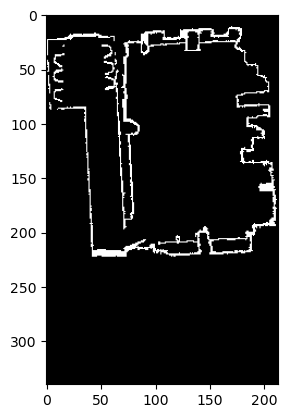

In [2]:
social_map_path = "/home/andrea/workspaces/appl_ws/social_evaluation/maps/covivio_v1.yaml"

map , map_info = get_map_data(social_map_path)
import matplotlib.pyplot as plt


plt.imshow(map, cmap='gray')
bag_path = get_bag_path('overtaking', 'DWA', '/home/andrea/workspaces/appl_ws/bags', 2)
df_obs = retrieve_obstacle_positions(map, map_info)
tf_msgs, _ = get_messages_from_bag(bag_path, '/tf')
df_tf= tf2_messages_to_df(tf_msgs)
laser_msgs, _ = get_messages_from_bag(bag_path, '/scan')
df_laser = laser_scan_to_df(laser_msgs)
transformations_map_base_link = []
for timestamp in filter_df_by_time(df_tf)['time']:
    
    transformations_map_base_link.append(
        pd.Series(
            {
                'time':timestamp,
                **get_pose_data_from_transform(get_transform_between_frames(df_tf, 'map', 'base_link', timestamp))}
                                               )
            )


df_map_base_link = pd.DataFrame(transformations_map_base_link)
df_map_base_link, dt = compute_odometry_data(df_map_base_link, period=5)
# df_map_base_link['closest_obs'] = find_closest_obstacle(df_map_base_link, df_obs)
df_map_base_link.dropna(inplace=True)
# df_map_base_link = find_closest_obstacle(df_map_base_link, df_obs)
# df_map_base_link["obstacle_force"] = compute_obstacle_force(df_map_base_link, df_obs)
df_map_base_link_ = df_map_base_link.copy()
obstacle_force = modulus_obstacle_force(df_map_base_link, df_obs)

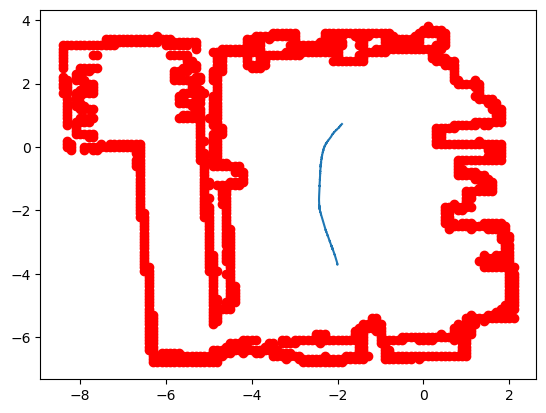

In [3]:
df_map_base_link2 = modulus_obstacle_force(df_map_base_link, df_obs)
fig, ax = plt.subplots()

# df_laser = laserscan_to_map_frame(df_laser, df_map_base_link)

x = np.array(df_map_base_link['position_x'])
y = np.array(df_map_base_link['position_y'])
time = np.array(df_map_base_link['time'])

ax.plot(x, y, label='robot path')
ax.scatter(df_obs['x'], df_obs['y'], label='obstacles', c='r')
# ax.scatter(df_map_base_link['closest_obs_x'], df_map_base_link['closest_obs_y'], label='closest obstacle', c='g')

In [4]:
df_map_base_link




,time,position_x,position_y,position_z,qx,qy,qz,qw,roll,pitch,yaw,velocity_x,velocity_y,velocity_z,angular_velocity_x,angular_velocity_y,angular_velocity_z
8,1.721308e+09,-2.006175,-3.704557,0.079581,-0.003610,-0.033843,0.746057,0.665012,-0.055370,-0.039636,1.686639,0.331363,-0.022853,-0.018457,-0.018474,-0.052056,0.540892
9,1.721308e+09,-2.004961,-3.717308,0.079060,-0.002706,-0.033736,0.746532,0.664489,-0.054037,-0.040805,1.688058,0.447684,-0.020917,-0.014460,-0.017530,-0.059883,0.664559
12,1.721308e+09,-2.011297,-3.670376,0.080423,-0.002999,-0.034386,0.760096,0.648893,-0.056240,-0.040076,1.729444,0.645500,-0.007281,-0.010844,0.001847,-0.044629,0.616772
14,1.721308e+09,-2.011297,-3.670376,0.080423,-0.002999,-0.034386,0.760096,0.648893,-0.056240,-0.040076,1.729444,0.625292,-0.006743,-0.010426,0.004717,-0.044961,0.635821
15,1.721308e+09,-2.005897,-3.689635,0.078612,-0.001517,-0.034363,0.754553,0.655337,-0.053920,-0.042763,1.712461,0.538539,-0.012599,-0.013685,0.011704,-0.049779,0.581536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1123,1.721308e+09,-1.911557,0.705661,0.062730,-0.016405,-0.021306,0.458516,0.888279,-0.048715,-0.022809,0.953579,0.203810,0.002289,-0.004807,-0.002654,0.020551,-0.271024
1124,1.721308e+09,-1.911557,0.705661,0.062730,-0.016405,-0.021306,0.458516,0.888279,-0.048715,-0.022809,0.953579,0.207608,0.001322,-0.004528,-0.002502,0.020967,-0.287811
1125,1.721308e+09,-1.912542,0.705546,0.062137,-0.017090,-0.021021,0.458901,0.888074,-0.049680,-0.021652,0.954433,0.210063,0.001608,-0.005087,-0.003802,0.023092,-0.301663
1127,1.721308e+09,-1.904006,0.716153,0.062473,-0.016824,-0.021234,0.447684,0.893781,-0.049120,-0.022895,0.929278,0.205339,0.002060,-0.005266,-0.004483,0.023494,-0.307651
